In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

print(os.listdir(data_path))

['Fake.csv', 'True.csv']


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:

data_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/data"

fake_df = pd.read_csv(data_path + "/Fake.csv")
true_df = pd.read_csv(data_path + "/True.csv")

fake_df["label"] = "Fake"
true_df["label"] = "Real"

df = pd.concat([fake_df, true_df], ignore_index=True)

print("Dataset loaded successfully!")
print("Total records:", len(df))

Dataset loaded successfully!
Total records: 44898


In [5]:

print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (44898, 5)

First Five Records:


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",Fake
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",Fake
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",Fake
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",Fake
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",Fake



Column Names:
['title', 'text', 'subject', 'date', 'label']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB


In [6]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nNews Label Distribution:")
print(df["label"].value_counts())

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate Records:
209

News Label Distribution:
label
Fake    23481
Real    21417
Name: count, dtype: int64


In [7]:

print("Missing values before cleaning:")
print(df.isnull().sum())

df_clean = df.copy()

# Fill missing titles with empty text
df_clean["title"] = df_clean["title"].fillna("")

# Remove records with missing article text or labels
df_clean = df_clean.dropna(subset=["text", "label"])

# Remove records where both title and article text are empty
df_clean = df_clean[
    (df_clean["title"].str.strip() != "") |
    (df_clean["text"].str.strip() != "")
]

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Missing values before cleaning:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Missing values after cleaning:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [8]:

print("Duplicates before removal:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates(
    subset=["title", "text", "label"]
)

df_clean = df_clean.reset_index(drop=True)

print("Duplicates after removal:", df_clean.duplicated(
    subset=["title", "text", "label"]
).sum())

print("Records after removing duplicates:", len(df_clean))

Duplicates before removal: 209
Duplicates after removal: 0
Records after removing duplicates: 39105


In [10]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z0-9\s.,!?\'"-]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df_clean["title"] = df_clean["title"].apply(clean_text)
df_clean["text"] = df_clean["text"].apply(clean_text)

print("Text cleaning completed successfully!")

Text cleaning completed successfully!


In [11]:

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nFirst five cleaned records:")
display(df_clean[["title", "text", "label"]].head())

print("\nFinal label distribution:")
print(df_clean["label"].value_counts())

Original dataset shape: (44898, 5)
Cleaned dataset shape: (39105, 5)

First five cleaned records:


,title,text,label
0,donald trump sends out embarrassing new years ...,donald trump just couldn t wish all americans ...,Fake
1,drunk bragging trump staffer started russian c...,house intelligence committee chairman devin nu...,Fake
2,sheriff david clarke becomes an internet joke ...,"on friday, it was revealed that former milwauk...",Fake
3,trump is so obsessed he even has obamas name c...,"on christmas day, donald trump announced that ...",Fake
4,pope francis just called out donald trump duri...,pope francis used his annual christmas day mes...,Fake



Final label distribution:
label
Real    21197
Fake    17908
Name: count, dtype: int64


In [12]:

# Count real and fake news articles

label_counts = df_clean["label"].value_counts()

print("News Category Distribution:")
print(label_counts)

print("\nPercentage Distribution:")
print(df_clean["label"].value_counts(normalize=True) * 100)

News Category Distribution:
label
Real    21197
Fake    17908
Name: count, dtype: int64

Percentage Distribution:
label
Real    54.205345
Fake    45.794655
Name: proportion, dtype: float64


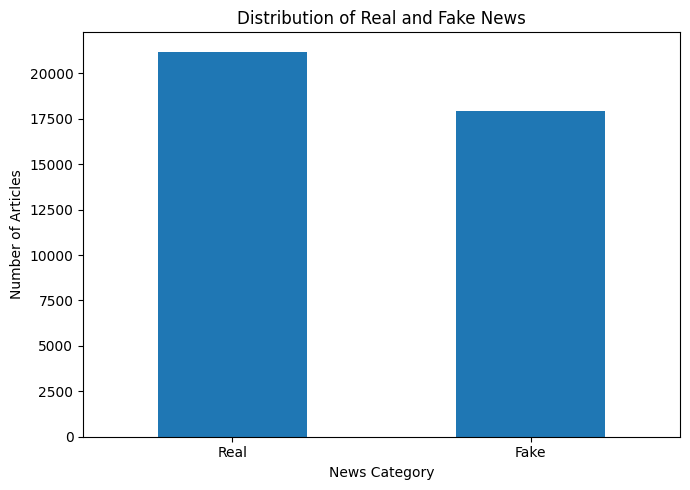

In [13]:

plt.figure(figsize=(7, 5))

label_counts.plot(kind="bar")

plt.title("Distribution of Real and Fake News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [14]:

# Calculate article length

df_clean["text_length"] = df_clean["text"].apply(len)

print("Article Length Statistics:")
print(df_clean["text_length"].describe())

Article Length Statistics:
count    39105.000000
mean      2401.665541
std       1919.517202
min          0.000000
25%       1253.000000
50%       2190.000000
75%       3051.000000
max      51339.000000
Name: text_length, dtype: float64


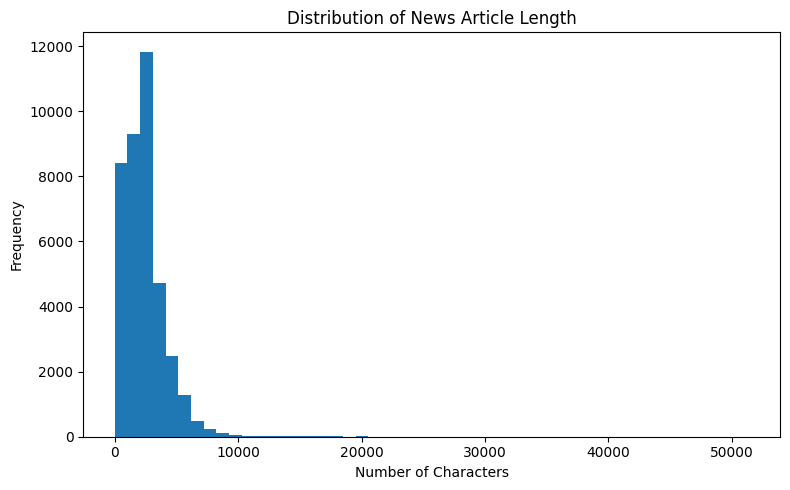

In [15]:

plt.figure(figsize=(8, 5))

plt.hist(df_clean["text_length"], bins=50)

plt.title("Distribution of News Article Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

<Figure size 700x500 with 0 Axes>

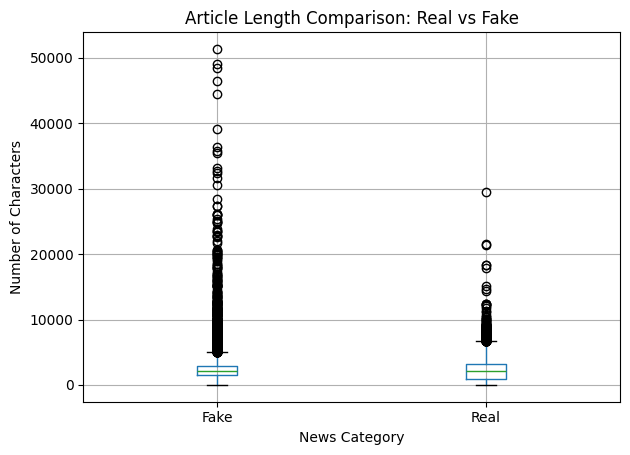

In [16]:

plt.figure(figsize=(7, 5))

df_clean.boxplot(
    column="text_length",
    by="label"
)

plt.title("Article Length Comparison: Real vs Fake")
plt.suptitle("")
plt.xlabel("News Category")
plt.ylabel("Number of Characters")

plt.tight_layout()
plt.show()

News Subject Distribution:
subject
politicsNews       11217
worldnews           9980
News                9050
politics            6838
US_News              783
left-news            705
Government News      532
Name: count, dtype: int64


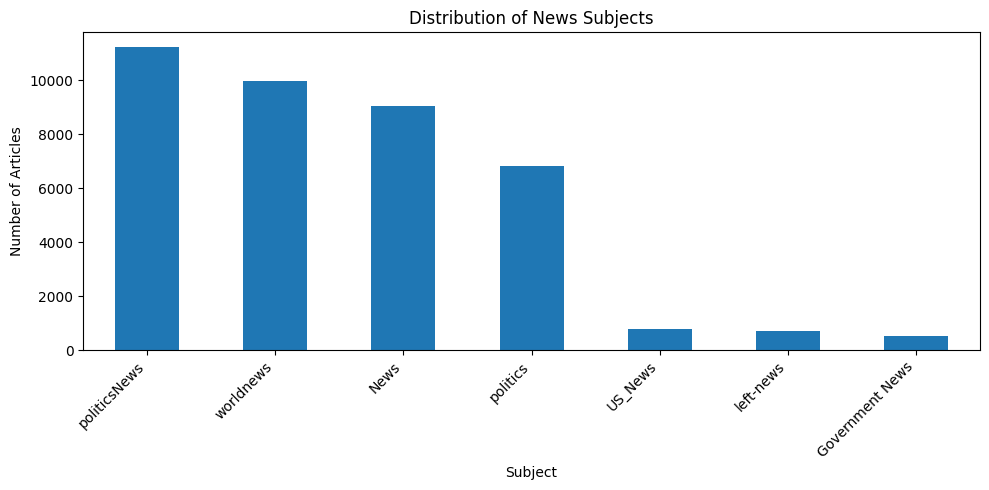

In [17]:

if "subject" in df_clean.columns:

    print("News Subject Distribution:")
    print(df_clean["subject"].value_counts())

    plt.figure(figsize=(10, 5))

    df_clean["subject"].value_counts().plot(
        kind="bar"
    )

    plt.title("Distribution of News Subjects")
    plt.xlabel("Subject")
    plt.ylabel("Number of Articles")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

else:
    print("Subject column is not available.")

In [18]:

import os

output_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/outputs/visualizations"

os.makedirs(output_path, exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


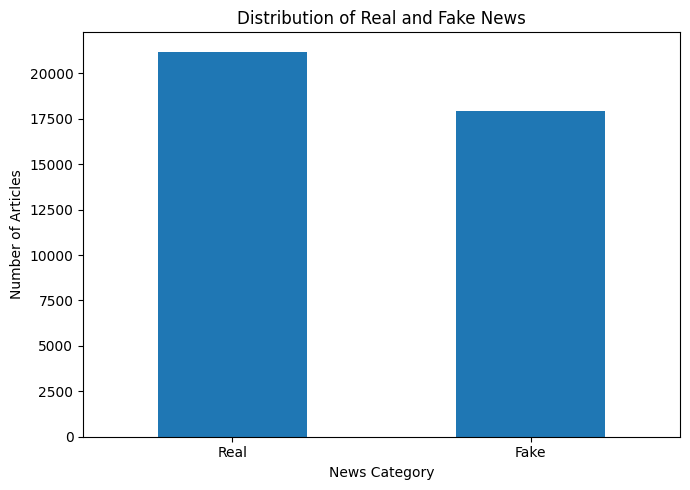

In [19]:
plt.figure(figsize=(7, 5))
df_clean["label"].value_counts().plot(kind="bar")
plt.title("Distribution of Real and Fake News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(output_path + "/label_distribution.png")
plt.show()

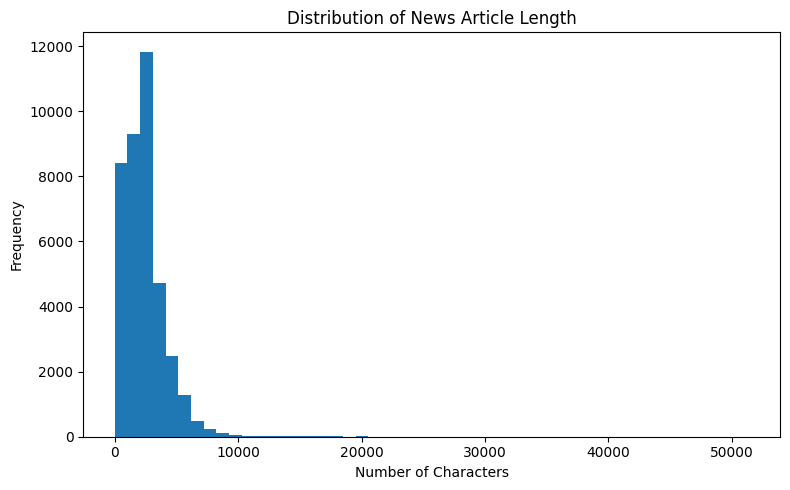

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["text_length"], bins=50)
plt.title("Distribution of News Article Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(output_path + "/article_length_histogram.png")
plt.show()

<Figure size 700x500 with 0 Axes>

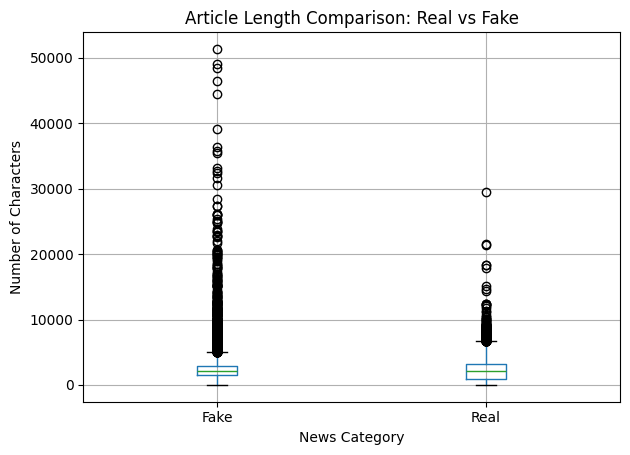

In [21]:
plt.figure(figsize=(7, 5))
df_clean.boxplot(column="text_length", by="label")
plt.title("Article Length Comparison: Real vs Fake")
plt.suptitle("")
plt.xlabel("News Category")
plt.ylabel("Number of Characters")
plt.tight_layout()

plt.savefig(output_path + "/article_length_comparison.png")
plt.show()

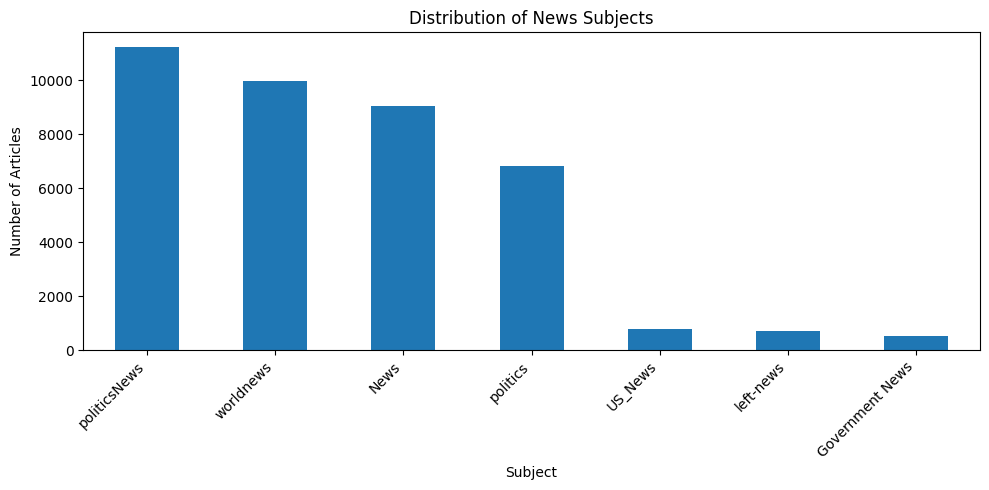

In [22]:
if "subject" in df_clean.columns:
    plt.figure(figsize=(10, 5))
    df_clean["subject"].value_counts().plot(kind="bar")
    plt.title("Distribution of News Subjects")
    plt.xlabel("Subject")
    plt.ylabel("Number of Articles")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(output_path + "/subject_distribution.png")
    plt.show()
else:
    print("Subject column is not available.")

In [23]:
print("Saved visualization files:")
print(os.listdir(output_path))

Saved visualization files:
['label_distribution.png', 'article_length_histogram.png', 'article_length_comparison.png', 'subject_distribution.png']


In [24]:
df_clean["content"] = df_clean["title"] + " " + df_clean["text"]

print("Title and article text combined successfully!")
display(df_clean[["title", "text", "content", "label"]].head())

Title and article text combined successfully!


,title,text,content,label
0,donald trump sends out embarrassing new years ...,donald trump just couldn t wish all americans ...,donald trump sends out embarrassing new years ...,Fake
1,drunk bragging trump staffer started russian c...,house intelligence committee chairman devin nu...,drunk bragging trump staffer started russian c...,Fake
2,sheriff david clarke becomes an internet joke ...,"on friday, it was revealed that former milwauk...",sheriff david clarke becomes an internet joke ...,Fake
3,trump is so obsessed he even has obamas name c...,"on christmas day, donald trump announced that ...",trump is so obsessed he even has obamas name c...,Fake
4,pope francis just called out donald trump duri...,pope francis used his annual christmas day mes...,pope francis just called out donald trump duri...,Fake


In [25]:
X = df_clean["content"]
y = df_clean["label"]

print("Features and labels separated successfully!")
print("Total articles:", len(X))
print("\nLabel distribution:")
print(y.value_counts())

Features and labels separated successfully!
Total articles: 39105

Label distribution:
label
Real    21197
Fake    17908
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Dataset split successfully!
Training records: 31284
Testing records: 7821


In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF vectorization completed successfully!")
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF vectorization completed successfully!
Training data shape: (31284, 5000)
Testing data shape: (7821, 5000)
Number of features: 5000


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

print("Machine learning models imported successfully!")

Machine learning models imported successfully!


In [30]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [31]:
naive_bayes_model = MultinomialNB()

naive_bayes_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [32]:
y_pred_logistic = logistic_model.predict(X_test_tfidf)

y_pred_nb = naive_bayes_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("Logistic Regression predictions:")
print(y_pred_logistic[:10])

print("\nNaive Bayes predictions:")
print(y_pred_nb[:10])

Predictions generated successfully!
Logistic Regression predictions:
['Fake' 'Fake' 'Real' 'Real' 'Real' 'Real' 'Fake' 'Real' 'Fake' 'Real']

Naive Bayes predictions:
['Fake' 'Fake' 'Real' 'Real' 'Real' 'Real' 'Fake' 'Real' 'Fake' 'Real']


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import os

results_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/outputs/evaluation_results"
os.makedirs(results_path, exist_ok=True)

print("Evaluation tools imported successfully!")
print("Evaluation results folder created successfully!")

Evaluation tools imported successfully!
Evaluation results folder created successfully!


In [34]:
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_logistic,
    labels=["Fake", "Real"],
    zero_division=0
))

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.99      3582
        Real       0.99      0.99      0.99      4239

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



In [35]:
print("MULTINOMIAL NAIVE BAYES - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_nb,
    labels=["Fake", "Real"],
    zero_division=0
))

MULTINOMIAL NAIVE BAYES - CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake       0.95      0.94      0.95      3582
        Real       0.95      0.96      0.96      4239

    accuracy                           0.95      7821
   macro avg       0.95      0.95      0.95      7821
weighted avg       0.95      0.95      0.95      7821



In [36]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ]
})

display(results)

results.to_csv(results_path + "/model_comparison.csv", index=False)

print("Model comparison saved successfully!")

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.990155,0.990179,0.990155,0.990151
1,Multinomial Naive Bayes,0.951413,0.951410,0.951413,0.951395


Model comparison saved successfully!


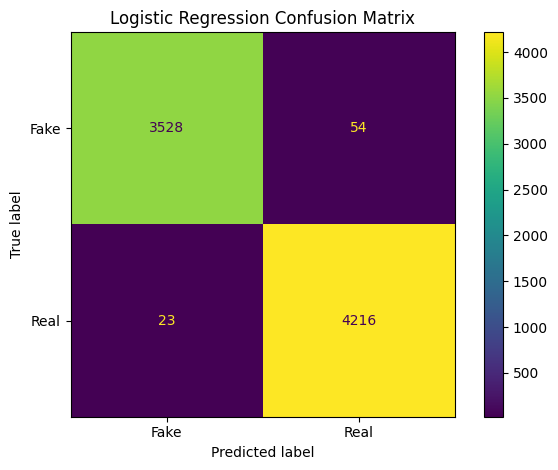

In [37]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Fake", "Real"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Fake", "Real"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(results_path + "/logistic_regression_confusion_matrix.png")
plt.show()

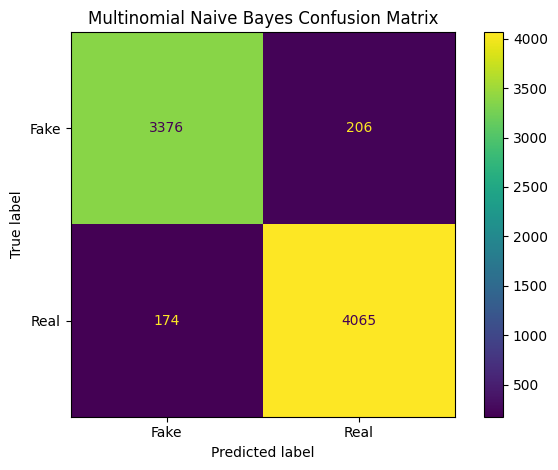

In [38]:
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=["Fake", "Real"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Fake", "Real"]
)

disp.plot()
plt.title("Multinomial Naive Bayes Confusion Matrix")
plt.tight_layout()

plt.savefig(results_path + "/naive_bayes_confusion_matrix.png")
plt.show()

In [39]:
print("Saved evaluation files:")
print(os.listdir(results_path))

Saved evaluation files:
['model_comparison.csv', 'logistic_regression_confusion_matrix.png', 'naive_bayes_confusion_matrix.png']


In [40]:
import os

models_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/models"

os.makedirs(models_path, exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [41]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [42]:
joblib.dump(
    logistic_model,
    models_path + "/logistic_regression_model.joblib"
)

print("Logistic Regression model saved successfully!")

Logistic Regression model saved successfully!


In [43]:
joblib.dump(
    naive_bayes_model,
    models_path + "/naive_bayes_model.joblib"
)

print("Naive Bayes model saved successfully!")

Naive Bayes model saved successfully!


In [44]:
joblib.dump(
    tfidf,
    models_path + "/tfidf_vectorizer.joblib"
)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


In [45]:
print("Files saved in the models folder:")

for file in os.listdir(models_path):
    print(file)

Files saved in the models folder:
logistic_regression_model.joblib
naive_bayes_model.joblib
tfidf_vectorizer.joblib


In [46]:
app_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/app"

os.makedirs(app_path, exist_ok=True)

print("App folder created successfully!")
print("Saved model files:")
print(os.listdir(models_path))

App folder created successfully!
Saved model files:
['logistic_regression_model.joblib', 'naive_bayes_model.joblib', 'tfidf_vectorizer.joblib']


In [47]:
%%writefile /content/drive/MyDrive/Smart_Fake_News_Detection/app/streamlit_app.py

import streamlit as st
import joblib
import re
import os

# Find the main project folder
BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Load saved models and vectorizer
logistic_model = joblib.load(
    os.path.join(MODEL_DIR, "logistic_regression_model.joblib")
)

naive_bayes_model = joblib.load(
    os.path.join(MODEL_DIR, "naive_bayes_model.joblib")
)

tfidf = joblib.load(
    os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib")
)

# Text preprocessing function
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z0-9\s.,!?\'"-]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Application heading
st.set_page_config(
    page_title="Smart Fake News Detection",
    page_icon="📰",
    layout="centered"
)

st.title("📰 Smart Fake News Detection System")

st.write(
    "Enter a news headline and article to see how "
    "a machine learning model classifies the text."
)

st.info(
    "This application uses machine learning and text patterns. "
    "It is not a definitive fact-checking service."
)

# User inputs
title = st.text_input("Enter News Headline")

article = st.text_area(
    "Enter News Article",
    height=250
)

# Model selection
model_choice = st.selectbox(
    "Select Machine Learning Model",
    [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ]
)

# Prediction button
if st.button("Detect News Category"):

    if not title.strip() and not article.strip():
        st.warning("Please enter a headline or news article.")

    else:
        cleaned_title = clean_text(title)
        cleaned_article = clean_text(article)

        content = cleaned_title + " " + cleaned_article

        transformed_text = tfidf.transform([content])

        if model_choice == "Logistic Regression":
            prediction = logistic_model.predict(transformed_text)[0]

        else:
            prediction = naive_bayes_model.predict(transformed_text)[0]

        st.subheader("Prediction Result")

        if prediction == "Fake":
            st.error("The model classified this news as: FAKE")

        else:
            st.success("The model classified this news as: REAL")

        st.caption(
            "This is a machine-learning prediction, not confirmation "
            "of whether the news is factually true or false."
        )

st.divider()

st.caption("Smart Fake News Detection System | Python, NLP and Machine Learning")

Writing /content/drive/MyDrive/Smart_Fake_News_Detection/app/streamlit_app.py


In [48]:
print("Files inside the app folder:")
print(os.listdir(app_path))

Files inside the app folder:
['streamlit_app.py']


In [49]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


In [50]:
requirements_content = f"""streamlit
scikit-learn=={sklearn.__version__}
joblib
"""

requirements_path = "/content/drive/MyDrive/Smart_Fake_News_Detection/requirements.txt"

with open(requirements_path, "w") as file:
    file.write(requirements_content)

print("requirements.txt created successfully!")
print(requirements_content)

requirements.txt created successfully!
streamlit
scikit-learn==1.6.1
joblib



In [51]:
project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

for folder, subfolders, files in os.walk(project_path):
    print("\nFolder:", folder)
    for file in files:
        print("  ", file)


Folder: /content/drive/MyDrive/Smart_Fake_News_Detection
   requirements.txt

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/data
   Fake.csv
   True.csv

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/outputs

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/outputs/visualizations
   label_distribution.png
   article_length_histogram.png
   article_length_comparison.png
   subject_distribution.png

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/outputs/evaluation_results
   model_comparison.csv
   logistic_regression_confusion_matrix.png
   naive_bayes_confusion_matrix.png

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/models
   logistic_regression_model.joblib
   naive_bayes_model.joblib
   tfidf_vectorizer.joblib

Folder: /content/drive/MyDrive/Smart_Fake_News_Detection/app
   streamlit_app.py


In [52]:
print("Checking saved model files...")

required_files = [
    "logistic_regression_model.joblib",
    "naive_bayes_model.joblib",
    "tfidf_vectorizer.joblib"
]

for file in required_files:
    file_path = os.path.join(models_path, file)

    if os.path.exists(file_path):
        print(file, "- Available")
    else:
        print(file, "- MISSING")

Checking saved model files...
logistic_regression_model.joblib - Available
naive_bayes_model.joblib - Available
tfidf_vectorizer.joblib - Available


In [53]:
loaded_logistic = joblib.load(
    models_path + "/logistic_regression_model.joblib"
)

loaded_nb = joblib.load(
    models_path + "/naive_bayes_model.joblib"
)

loaded_tfidf = joblib.load(
    models_path + "/tfidf_vectorizer.joblib"
)

print("All saved models and vectorizer loaded successfully!")

All saved models and vectorizer loaded successfully!


In [54]:
sample_news = "This is a sample news article used to test the prediction system."

sample_cleaned = clean_text(sample_news)

sample_vector = loaded_tfidf.transform([sample_cleaned])

print("Logistic Regression test prediction:")
print(loaded_logistic.predict(sample_vector)[0])

print("\nMultinomial Naive Bayes test prediction:")
print(loaded_nb.predict(sample_vector)[0])

print("\nModel testing completed successfully!")

Logistic Regression test prediction:
Fake

Multinomial Naive Bayes test prediction:
Real

Model testing completed successfully!


In [55]:
app_file = os.path.join(app_path, "streamlit_app.py")

if os.path.exists(app_file):
    with open(app_file, "r") as file:
        app_code = file.read()

    compile(app_code, app_file, "exec")

    print("Streamlit application file exists!")
    print("Python syntax check passed successfully!")
else:
    print("Streamlit application file is missing!")

Streamlit application file exists!
Python syntax check passed successfully!


In [56]:
import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

print("PROJECT FILE SIZES")
print("-------------------")

for folder, subfolders, files in os.walk(project_path):
    for file in files:
        file_path = os.path.join(folder, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)

        print(file, ":", round(size_mb, 2), "MB")

PROJECT FILE SIZES
-------------------
requirements.txt : 0.0 MB
Fake.csv : 59.88 MB
True.csv : 51.1 MB
label_distribution.png : 0.02 MB
article_length_histogram.png : 0.02 MB
article_length_comparison.png : 0.03 MB
subject_distribution.png : 0.03 MB
model_comparison.csv : 0.0 MB
logistic_regression_confusion_matrix.png : 0.02 MB
naive_bayes_confusion_matrix.png : 0.03 MB
logistic_regression_model.joblib : 0.04 MB
naive_bayes_model.joblib : 0.15 MB
tfidf_vectorizer.joblib : 0.18 MB
streamlit_app.py : 0.0 MB


In [57]:
print("MAIN PROJECT FOLDERS")
print("--------------------")

for item in os.listdir(project_path):
    full_path = os.path.join(project_path, item)

    if os.path.isdir(full_path):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)

MAIN PROJECT FOLDERS
--------------------
[FOLDER] data
[FOLDER] outputs
[FOLDER] models
[FOLDER] app
[FILE] requirements.txt


In [58]:
gitignore_content = """# Large datasets
data/*.csv

# Python temporary files
__pycache__/
*.pyc

# Jupyter temporary files
.ipynb_checkpoints/

# System files
.DS_Store

# Private environment files
.env
"""

gitignore_path = os.path.join(project_path, ".gitignore")

with open(gitignore_path, "w") as file:
    file.write(gitignore_content)

print(".gitignore created successfully!")

.gitignore created successfully!


In [61]:
readme_content = """# Smart Fake News Detection System

## Project Overview

The Smart Fake News Detection System is a machine learning project
that uses Natural Language Processing (NLP) and Python to classify
news articles as Fake or Real based on their textual content.

The project uses TF-IDF vectorization and compares two machine
learning algorithms:
- Logistic Regression
- Multinomial Naive Bayes

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Natural Language Processing (NLP)
- TF-IDF
- Streamlit
- Joblib

## Dataset

The project uses the Fake and Real News Dataset by Clément Bisaillon.

Kaggle dataset:
https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset

Download the dataset and place Fake.csv and True.csv inside the data folder.

The original CSV files are not included in this GitHub repository because
of their size.

## Project Structure

```text
Smart_Fake_News_Detection/
|
|-- data/
|   |-- Fake.csv
|   |-- True.csv
|
|-- models/
|   |-- logistic_regression_model.joblib
|   |-- naive_bayes_model.joblib
|   |-- tfidf_vectorizer.joblib
|
|-- app/
|   |-- streamlit_app.py
|
|-- outputs/
|   |-- visualizations/
|   |-- evaluation_results/
|
|-- requirements.txt
|-- README.md
|-- .gitignore
```
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [64]:
for file in [".gitignore", "README.md"]:
    file_path = os.path.join(project_path, file)
    print(file, ":", "Created" if os.path.exists(file_path) else "Missing")

.gitignore : Created
README.md : Created


In [65]:
import os

project_path = "/content/drive/MyDrive/Smart_Fake_News_Detection"

print("FINAL PROJECT STRUCTURE")
print("========================")

for folder, subfolders, files in os.walk(project_path):
    level = folder.replace(project_path, "").count(os.sep)
    indent = "    " * level

    print(indent + os.path.basename(folder) + "/")

    for file in files:
        print(indent + "    " + file)

FINAL PROJECT STRUCTURE
Smart_Fake_News_Detection/
    requirements.txt
    .gitignore
    README.md
    data/
        Fake.csv
        True.csv
    outputs/
        visualizations/
            label_distribution.png
            article_length_histogram.png
            article_length_comparison.png
            subject_distribution.png
        evaluation_results/
            model_comparison.csv
            logistic_regression_confusion_matrix.png
            naive_bayes_confusion_matrix.png
    models/
        logistic_regression_model.joblib
        naive_bayes_model.joblib
        tfidf_vectorizer.joblib
    app/
        streamlit_app.py


In [66]:
import os

drive_path = "/content/drive/MyDrive"

print("Searching for your project notebook...")

for folder, subfolders, files in os.walk(drive_path):
    for file in files:
        if file.endswith(".ipynb") and "fake_news" in file.lower():
            print(os.path.join(folder, file))

Searching for your project notebook...
/content/drive/MyDrive/Colab Notebooks/fake_news_analysis.ipynb


In [68]:
import os

colab_path = "/content/drive/MyDrive/Colab Notebooks"

if os.path.exists(colab_path):
    for file in os.listdir(colab_path):
        if file.endswith(".ipynb"):
            print("Notebook found:", file)
            print("Full path:", os.path.join(colab_path, file))
else:
    print(f"Directory not found: {colab_path}")
    print("Please verify your Google Drive folder structure.")

Notebook found: fake_news_analysis.ipynb
Full path: /content/drive/MyDrive/Colab Notebooks/fake_news_analysis.ipynb
Notebook found: Untitled0.ipynb
Full path: /content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
